## IMPORT LIBRARY

In [1]:
#202431013_Tashfia Wahdah Fuady
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

## MEMBACA DATASET

In [2]:
#202431013_Tashfia Wahdah Fuady
df = pd.read_excel('Luas_Panen_Hias_2019-2023.xlsx', sheet_name='Hias')
df

,No,Tanaman,Satuan,2019,2020,2021,2022,2023
0,1,Aglaonema,Pohon,134778.0,159673.0,256590.0,179133.0,200605.0
1,2,Anggrek,Tangkai,1760096.0,953841.0,NaN,NaN,NaN
2,3,Anggrek Pot,Pohon,NaN,NaN,569571.0,533046.0,532571.0
3,4,Anggrek Potong,Tangkai,NaN,NaN,360837.0,223592.0,133177.0
4,5,Anthurium Bunga,Pohon,NaN,NaN,146984.0,133284.0,171811.0
5,6,Anthurium Bunga,Tangkai,265679.0,133815.0,NaN,NaN,NaN
6,7,Bromelia,Pohon,NaN,NaN,15382.0,36398.0,26804.0
7,8,Bugenvil,Pohon,NaN,NaN,68077.0,101988.0,49185.0
8,9,Cordyline,Pohon,59560.0,36869.0,67951.0,46088.0,25614.0
9,10,Dracaena,Pohon,279909.0,205254.0,277160.0,331180.0,276429.0


## EDA

In [3]:
df.head()

,No,Tanaman,Satuan,2019,2020,2021,2022,2023
0,1,Aglaonema,Pohon,134778.0,159673.0,256590.0,179133.0,200605.0
1,2,Anggrek,Tangkai,1760096.0,953841.0,NaN,NaN,NaN
2,3,Anggrek Pot,Pohon,NaN,NaN,569571.0,533046.0,532571.0
3,4,Anggrek Potong,Tangkai,NaN,NaN,360837.0,223592.0,133177.0
4,5,Anthurium Bunga,Pohon,NaN,NaN,146984.0,133284.0,171811.0


In [4]:
df.shape

(24, 8)

In [5]:
df.describe()

,No,2019,2020,2021,2022,2023
count,24.000000,1.600000e+01,1.600000e+01,2.000000e+01,2.000000e+01,2.000000e+01
mean,12.500000,2.181501e+06,2.000792e+06,1.449290e+06,1.501158e+06,1.429074e+06
std,7.071068,3.681360e+06,3.437930e+06,2.981990e+06,2.725658e+06,2.666101e+06
min,1.000000,5.956000e+04,3.686900e+04,1.204000e+04,3.639800e+04,2.561400e+04
25%,6.750000,1.858845e+05,1.471815e+05,1.021475e+05,1.118648e+05,9.366475e+04
50%,12.500000,3.330925e+05,3.629145e+05,2.668750e+05,2.013625e+05,1.862080e+05
75%,18.250000,2.208617e+06,1.617076e+06,6.053020e+05,5.481075e+05,5.011595e+05
max,24.000000,1.177940e+07,1.145018e+07,1.215418e+07,9.043099e+06,8.483951e+06


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   No       24 non-null     int64  
 1   Tanaman  24 non-null     str    
 2   Satuan   24 non-null     str    
 3   2019     16 non-null     float64
 4   2020     16 non-null     float64
 5   2021     20 non-null     float64
 6   2022     20 non-null     float64
 7   2023     20 non-null     float64
dtypes: float64(5), int64(1), str(2)
memory usage: 2.1 KB


In [7]:
df.isna().sum()

No         0
Tanaman    0
Satuan     0
2019       8
2020       8
2021       4
2022       4
2023       4
dtype: int64

### Visualisasi Boxplot untuk melihat sebaran data dan indikasi outlier

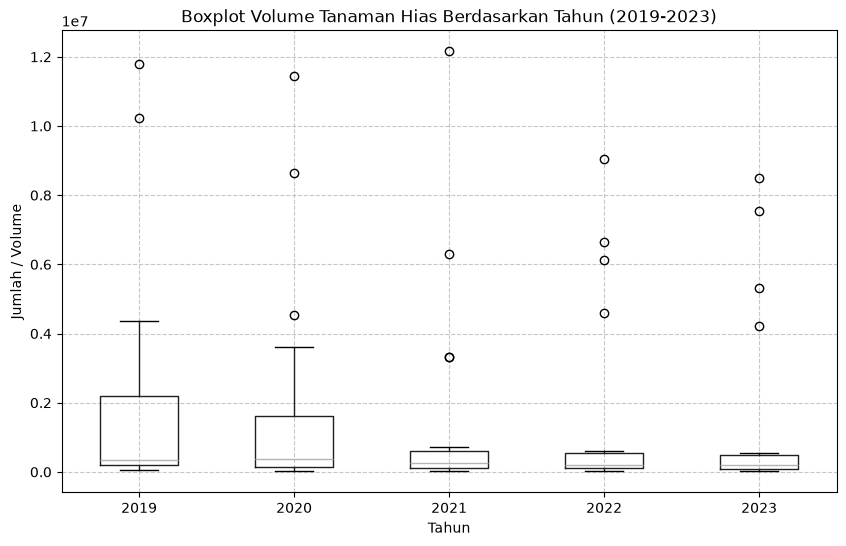

In [8]:
#202431013_Tashfia Wahdah Fuady
plt.figure(figsize=(10, 6))
df.boxplot(column=[2019, 2020, 2021, 2022, 2023])
plt.title(
    'Boxplot Volume Tanaman Hias Berdasarkan Tahun (2019-2023)', fontsize=12
)
plt.xlabel('Tahun')
plt.ylabel('Jumlah / Volume')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### Visualisasi Matriks Korelasi Antar Tahun

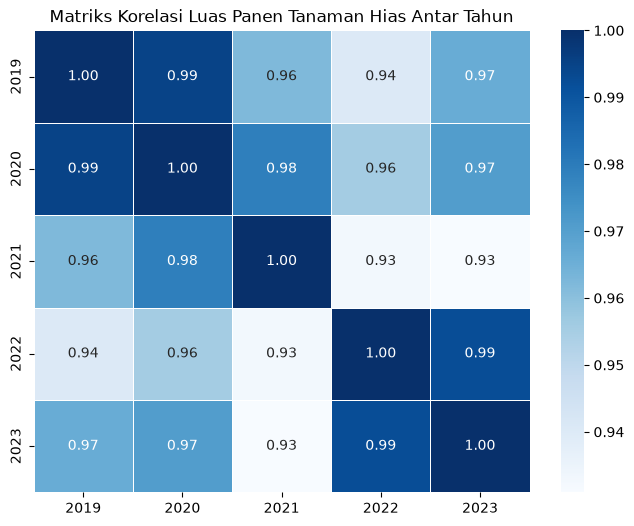

In [18]:
#202431013_Tashfia Wahdah Fuady
plt.figure(figsize=(8, 6))

sns.heatmap(
    df_clean[year_cols].corr(),
    annot=True,
    cmap='Blues',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Matriks Korelasi Luas Panen Tanaman Hias Antar Tahun')
plt.show()

## DATA PREPARATION & PREPROCESSING

In [9]:
year_cols = [2019, 2020, 2021, 2022, 2023]

### Penanganan Missing Value 

In [10]:
#202431013_Tashfia Wahdah Fuady
df_clean = df.dropna(subset=year_cols).copy()
print(f'Jumlah baris sebelum pembersihan: {len(df)}')
print(f'Jumlah baris setelah membersihkan missing value: {len(df_clean)}')

Jumlah baris sebelum pembersihan: 24
Jumlah baris setelah membersihkan missing value: 12


### Pengecekan Outlier Menggunakan Metode IQR

In [11]:
#202431013_Tashfia Wahdah Fuady
print('\n--- Pengecekan Outlier (IQR) ---')
for col in year_cols:
  Q1 = df_clean[col].quantile(0.25)
  Q3 = df_clean[col].quantile(0.75)
  IQR = Q3 - Q1
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR
  outliers = df_clean[
      (df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)
  ]
  print(f'Tahun {col}: Ditemukan {len(outliers)} data outlier.')

print(
    '\nStatus: Data sudah bersih (*cleaned*) dan siap masuk ke tahap'
    ' pemodelan.'
)


--- Pengecekan Outlier (IQR) ---
Tahun 2019: Ditemukan 2 data outlier.
Tahun 2020: Ditemukan 1 data outlier.
Tahun 2021: Ditemukan 1 data outlier.
Tahun 2022: Ditemukan 0 data outlier.
Tahun 2023: Ditemukan 0 data outlier.

Status: Data sudah bersih (*cleaned*) dan siap masuk ke tahap pemodelan.


In [12]:
#202431013_Tashfia Wahdah Fuady
df_model = df.dropna(subset=[2022, 2023]).copy()

print('--- Dataset Khusus Pemodelan ---')
print(f'Jumlah data sebelum preprocessing: {len(df)}')
print(f'Jumlah data setelah preprocessing: {len(df_model)}')
print(f'Jumlah data yang dihapus: {len(df) - len(df_model)}')

# Memeriksa missing value
print('\nMissing Value:')
print(df_model[[2022, 2023]].isna().sum())

# Menampilkan data yang akan digunakan
df_model[['Tanaman', 2022, 2023]]

--- Dataset Khusus Pemodelan ---
Jumlah data sebelum preprocessing: 24
Jumlah data setelah preprocessing: 20
Jumlah data yang dihapus: 4

Missing Value:
2022    0
2023    0
dtype: int64


,Tanaman,2022,2023
0,Aglaonema,179133.0,200605.0
2,Anggrek Pot,533046.0,532571.0
3,Anggrek Potong,223592.0,133177.0
4,Anthurium Bunga,133284.0,171811.0
6,Bromelia,36398.0,26804.0
7,Bugenvil,101988.0,49185.0
8,Cordyline,46088.0,25614.0
9,Dracaena,331180.0,276429.0
10,Gerbera (Herbras),491280.0,490689.0
11,Heliconia (Pisang-Pisangan),115157.0,103927.0


## PEMODELAN MACHINE LEARNING (REGRESI LINIER)

### Menggunakan tahun 2022 sebagai Fitur (X) dan tahun 2023 sebagai Target (y)

In [13]:
#202431013_Tashfia Wahdah Fuady
X = df_model[[2022]]
y = df_model[2023]

print('Jumlah data fitur (X):', len(X))
print('Jumlah data target (y):', len(y))

Jumlah data fitur (X): 20
Jumlah data target (y): 20


### Train-Test Split (75% data latih, 25% data uji)

In [14]:
#202431013_Tashfia Wahdah Fuady
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

print('Jumlah data training:', len(X_train))
print('Jumlah data testing:', len(X_test))

Jumlah data training: 15
Jumlah data testing: 5


### Inisialisasi dan Training Model

In [15]:
#202431013_Tashfia Wahdah Fuady
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.97]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.739e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[11449073.88]


### Prediksi dan Evaluasi

In [16]:
#202431013_Tashfia Wahdah Fuady
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print('\n--- Hasil Evaluasi Performa Model ---')
print(f'Koefisien Regresi (Slope): {model.coef_[0]:.4f}')
print(f'Intercept: {model.intercept_:.4f}')
print(f'Mean Absolute Error (MAE): {mae:.4f}')
print(f'R-Squared (R² Score): {r2:.4f}')


--- Hasil Evaluasi Performa Model ---
Koefisien Regresi (Slope): 0.9742
Intercept: -47392.4632
Mean Absolute Error (MAE): 55972.8023
R-Squared (R² Score): 0.9110


## Visualisasi Hasil Prediksi

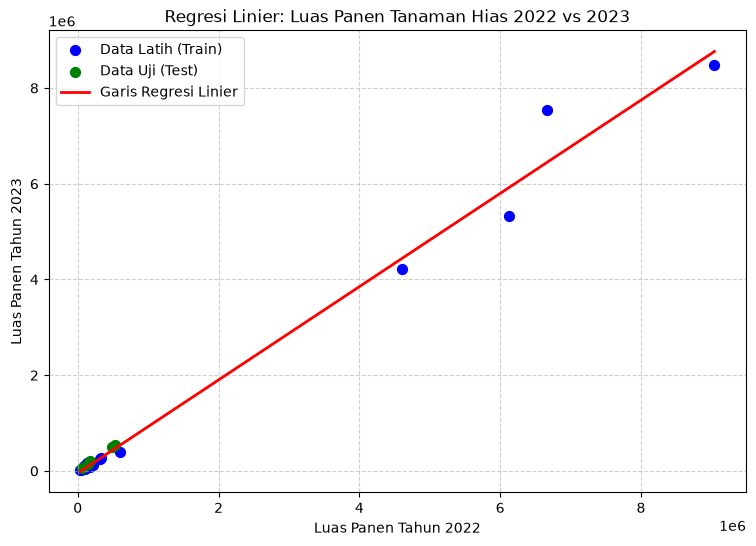

In [17]:
#202431013_Tashfia Wahdah Fuady
plt.figure(figsize=(9, 6))
plt.scatter(X_train, y_train, color='blue', label='Data Latih (Train)', s=50)
plt.scatter(X_test, y_test, color='green', label='Data Uji (Test)', s=50)

# Garis regresi
X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_range_pred = model.predict(X_range)
plt.plot(X_range, y_range_pred, color='red', linewidth=2, label='Garis Regresi Linier')

plt.title('Regresi Linier: Luas Panen Tanaman Hias 2022 vs 2023', fontsize=12)
plt.xlabel('Luas Panen Tahun 2022', fontsize=10)
plt.ylabel('Luas Panen Tahun 2023', fontsize=10)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()